# Fed-hike tail, today's trade: where do the SR3 put and its Polymarket hedge stand?

## S0 · Summary

**This is the read of its run date and time** (stamped in S1.3 and S7, CME quotes 10 minutes delayed). It is re-run as a new read, never as a replication of an earlier one; S7 sets the registered 2026-10-04 read beside it.

**The trade**

- We **sell SR3 puts** on CME that expire just after the next Fed meeting. We get paid now, and we lose if the Fed does
  **more** than the market expects.
- We **buy Polymarket YES** on that surprise: the hike outcomes bigger than the market's most likely one. Each pays USD 1
  if it happens.
- It's worth doing if CME pays us more for that risk than Polymarket charges to cover it.

**What this is, and isn't**

- A snapshot of **today's** prices and what each Fed outcome would do to us. **Not a backtest**: no past P&L, no win rate.
- SR3 prices are TradingView's quotes, CME **10 minutes delayed**: we sell the put at the bid and buy the hedge at the ask. A quote is not a fill, and the put we sell has barely traded (S2 says how much).
- Each scenario holds the market's view of the LATER meetings where it is today.

The block below is filled by the last cell of S7.

In [1]:
from IPython.display import Markdown, display
S0_HANDLE = display(Markdown("_S0 is rendered by the last cell of S7 when the run finishes._"), display_id=True)

**Fed-hike tail, today's trade: where do the SR3 put and its Polymarket hedge stand?** · **CHECK DATA**

**Research question** Does CME pay more for a surprise Fed hike than Polymarket charges to cover it, and what does each outcome do to the hedged put?

CHECK DATA. Read 2026-10-05 12:09Z: CME pays 22.0% for more than No change, Polymarket charges 17.5c, a gap of +377 bp after the hedge cost. 1 data check failed, so no gap is called.

**Implementation**

| | |
|:--|:--|
| Trade | Short 40 SR3 puts, long Polymarket hike YES |
| Put | SR3 2026-11-13 95.5000, sold at the bid |
| Hedge | Polymarket YES at the ask, sized to the put's loss |
| Prices | CME 10 min late [API]; Polymarket live [API] |
| Capital | USD 1,000,000; every return is on that |
| Read | 2026-10-05 12:09Z; a snapshot, not a backtest |

**The numbers that matter**

| At | Metric | Value | Bar | |
|:--|:--|--:|:--|:--|
| gap | CME minus Polymarket, after hedge cost | +377 bp | hurdle 100 bp; data fails | INFO |
| 40 lots | Net if the Fed does what is priced | USD +401 |  | INFO |
| worst | Worst listed outcome, of equity | +0.04% |  | INFO |
| hedge | Loss-matched hedge filled | 100% | under 20c | PASS |

**The gap**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| CME implies | 22.0% |  |  |
| Polymarket ask | 17.5c |  |  |
| Gap before costs | +450 bp |  |  |
| Cost of the hedge side | 73.0 bp |  |  |
| Gap after hedge cost | +377 bp | at least 100 bp | PASS |
| Median gap, 5 outcomes | +168.5 bp |  |  |
| Outcomes compared | 5 |  |  |

**Returns, 40 lots**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Premium in | USD 500 |  |  |
| Hedge out | USD 99 |  |  |
| Net in every listed outcome | USD +401 |  |  |
| Of equity | +0.04% |  |  |
| Expected at Polymarket's odds, ann. | +0.4% |  |  |

**Data checks**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Puts with two-sided quotes | 39 of 92 | 92 of 92 | FLAG |
| No-arbitrage checks passed | 330 of 346 | 346 of 346 | FAIL |
| Lots the put has printed | 4 of 40 | at least 40 lots | FLAG |
| Scenario checks passed | 20 of 20 |  |  |

**Hedge and December trade**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Capacity at today's asks | USD 95 |  |  |
| Worst December path, net | USD +77 |  |  |
| Chance of that path | 57.89% |  |  |

**Size**

| Lots, information only | Net in every listed outcome | Annualised | Verdict |
|:--|--:|--:|:--|
| 10 | USD +100 | +0.1% | INFO |
| 20 | USD +200 | +0.2% | INFO |
| **40** | **USD +401** | **+0.4%** | **INFO** |
| 80 | USD +801 | +0.7% | INFO |
| 160 | USD +1,602 | +1.5% | INFO |

Next test: re-read the gap daily for the next 5 trade dates; a gap that holds above the bar is the case for the trade.  
Not a fill: the quotes are CME 10 minutes late and the put has printed 4 lots against 40 to sell.  
Not a backtest: no past P&L or win rate; later meetings are held as priced; two-meeting chances assume independence.


## S1 · Setup

| question | gate |
|---|---|
| What exactly is the trade today, and on which prices? | every venue number is a fact card or a price read in this run, with its time |

### S1.1 · Parameters

In [2]:
# ---- parameters: owner-set, study-set or [U]; never a venue number ----
STUDY_ID = "2026-09-27-xasset-sofr-hike-tail-scenario"
RUN_ID = "research-008"                  # pre-registered in lab/research/results-log.md before this runs
KIND, DESK = "strategy", "lab/research"
TITLE = "Fed-hike tail, today's trade: where do the SR3 put and its Polymarket hedge stand?"
QUESTION = ("Does CME pay more for the risk of a surprise Fed hike at the next meeting than Polymarket charges to cover it, "
            "on today's prices, and what does each outcome do to a short SR3 put hedged on Polymarket?")
EQUITY = 1_000_000.0       # owner: the capital every return is measured on
LOTS = 40                  # owner 2026-09-27: 40 SR3 puts
LOT_SIZES = (10, 20, 40, 80, 160)   # [U] the sizes-and-returns table
STRIKE_BELOW_BP = 25.0     # [U] the put sits about one 25 bp surprise below today's futures price
OWN_YES = 22013            # owner 2026-09-27: the YES count in the trade as sent
OWN_EXPIRY_MONTH, OWN_STRIKE = "202612", 95.4375   # owner 2026-09-27: SR3 Dec-26 95.4375 put (S6)
UNDERLYING = "CME:SR3Z2026"   # [U] the future the front meeting's first option expiry exercises into (the Nov-13 and Dec-11 options sit on the Dec future)
MAX_SPREAD_PTS = 0.0100    # [U] a put quote wider than this, in points (1 point = 100 bp), is flagged
HISTORY_FROM = "2026-08-01"   # [U] how far back the put's prints and Polymarket's history are read
WALK_CAP = 0.20            # [U] the highest Polymarket ask a hedge walk will pay
GAP_MIN_BPS = 100.0        # [U] a GAP needs CME's implied chance above Polymarket's all-in price by this, bp of USD 1

### S1.2 · Assumptions

| item | what the run uses | source |
|---|---|---|
| SR3 contract terms | USD per bp per contract, strike grid, expiries | CME fact cards, read below with their tags |
| SR3 quotes | the live bid and ask per option; the future's daily settlements | TradingView, CME **10 minutes delayed** |
| the prices we trade at | the put at the BID, the hedge at the ASK | real two-sided quotes |
| a scenario | the front meeting's decision moves the futures by its surprise (decision minus what was priced); later meetings stay as priced | `sr3_scenarios` |
| each scenario's chance | Polymarket's mid, over the ladder's sum | [API] |
| two meetings | the product of the two meetings' chances | [U]: Polymarket prices each meeting alone |
| returns | net USD / equity; annualised x 365 / days to the option's expiry | S1.1 |

In [3]:
import datetime as dt, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from fundplat.data.tradfi import tradingview as TV, refrates as REFR, fedpolicy as FP
from fundplat.data.predmkts import polymarket as PM
from fundplat.data import handle as HD
from fundplat.quant.predmkts import match as MATCH
from fundplat.quant.tradfi import sr3_scenarios as SC
from fundplat.quant.core import report as REPORT, figstyle
from venues import facts as FACTS

warnings.filterwarnings("ignore", category=DeprecationWarning)


def _to_markdown(self, index=True, floatfmt=".2f", **_):
    # tabulate is not in the fund venv: pandas' to_markdown is replaced by this pipe-table writer (presentation only)
    d = self.reset_index() if index else self
    fmt = lambda v: format(v, floatfmt) if isinstance(v, (float, np.floating)) and np.isfinite(v) else ("" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
    rows = [[fmt(v) for v in r] for r in d.itertuples(index=False, name=None)]
    head = [str(c) for c in d.columns]
    return "\n".join(["| " + " | ".join(head) + " |", "|" + "|".join("---" for _ in head) + "|"] + ["| " + " | ".join(r) + " |" for r in rows])


pd.DataFrame.to_markdown = _to_markdown

NOW = dt.datetime.now(dt.timezone.utc)
RUN_AT = NOW.strftime("%Y-%m-%d %H:%MZ")
CARD_FACTS = {k: FACTS.tagged("cme", c) for k, c in {"USD per bp per contract": "contract.multiplier_and_inverse",
                                               "strike grid": "option.strike.intervals", "expiries": "expiry.times"}.items()}
USD_PER_BP = float(CARD_FACTS["USD per bp per contract"]["value"])
DELAY = FACTS.tagged("tradingview", "delay.cme")       # how late TradingView serves CME without a subscription, seconds
DELAY_MIN = int(DELAY["value"]) // 60
assert DELAY_MIN == 10, f"the S0 / S1 prose says 10 minutes; the fact card says {DELAY_MIN}"

INK, GRID, AXIS, MUTED = figstyle.NEUTRAL["ink"], figstyle.NEUTRAL["grid"], figstyle.NEUTRAL["axis"], figstyle.NEUTRAL["ink2"]
C_PUT, C_HEDGE = figstyle.IDENTITY["SKHY"], figstyle.IDENTITY["SKHX"]   # the two legs keep one identity colour in every figure: put blue, hedge amber
C_SIZES = (figstyle.NEUTRAL["muted"], figstyle.NEUTRAL["ink2"], figstyle.NEUTRAL["ink"])   # hedge sizes are neutral shades: green and red are for good and bad only
WIN_RE = r"\d{4}-\d\d-\d\d \d\d:\d\dZ"   # a snapshot's window is the read stamp
plt.rcParams.update({"figure.dpi": 96, "axes.edgecolor": AXIS, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
USD = FuncFormatter(lambda v, _: f"{v:,.0f}")
FIGURES = []


def ask(ax, q, sub):
    ax.set_title(q, loc="left", fontsize=11, fontweight="bold", color=INK, pad=18)
    ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=8, color=MUTED, va="bottom")


def show(f, tag, findings, top=0.80, kind=None):
    # findings below the chart, the figure rules checked, the figure listed for the manifest (figstyle.show, with the snapshot's window)
    w, h = f.get_size_inches()
    f.set_size_inches(w, h + figstyle.nlines(findings) * figstyle.LINE_IN + 0.5)
    figstyle.finish(f, findings, top)
    figstyle.check(f, tag, window_re=WIN_RE)
    FIGURES.append({"id": tag, "section": f"S{tag[5]}", "title": figstyle.title_of(f).strip(), **({"kind": kind} if kind else {})})   # kind = the chart type's slug in charts.md
    plt.show()


def netbars(ax, T, labels):
    # one bar per scenario: the put and the hedge stacked, the net as a black line (drawing only; every number is T's)
    x = np.arange(len(T))
    ax.bar(x, T.put_pnl_usd, .55, color=C_PUT, label="short put")
    same = np.sign(T.put_pnl_usd) == np.sign(T.hedge_pnl_usd)
    ax.bar(x, T.hedge_pnl_usd, .55, bottom=np.where(same, T.put_pnl_usd, 0), color=C_HEDGE, label="hedge")
    ax.hlines(T.net_usd, x - .36, x + .36, color=INK, lw=3, label="net")
    for xi, v in zip(x, T.net_usd):
        ax.text(xi, v, f" {v:,.0f}", fontsize=8, va="bottom" if v >= 0 else "top", ha="center")
    ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(x, labels); ax.yaxis.set_major_formatter(USD)
    ax.legend(frameon=False, ncol=3, loc="upper left")


display(Markdown("| card | value | tag | read |\n|---|---|---|---|\n" + "\n".join(
    f"| {k} | {str(c['value'])[:90]} | {c['tag']} | {c['read']} |" for k, c in CARD_FACTS.items())))

| card | value | tag | read |
|---|---|---|---|
| USD per bp per contract | 25.0 | [U] | 2026-09-27 |
| strike grid | Rule 460A01.E.3 as amended effective trade date 2020-10-12 (CME's filing to the CFTC): 6.2 | [1] | 2026-09-27 |
| expiries | Futures: the Reference Quarter runs from the third Wednesday of the contract month to the  | [U] | 2026-09-27 |

### S1.3 · Data

| source | what | guard |
|---|---|---|
| `fundplat.data.tradfi.tradingview.option_chain` and `fundplat.data.handle` | the live SR3 put chain (bid, ask, IV), the future's daily settlements, the put's own prints | an empty chain raises; a quote wider than the S1.1 limit is flagged, never dropped |
| `fundplat.data.tradfi.fedpolicy` | the Fed's meeting calendar and target range | the Fed's own |
| `fundplat.data.tradfi.refrates` | SOFR, the NY Fed | latest value date shown |
| `fundplat.data.predmkts.polymarket` | the open "Fed Decision in ...?" markets: live books and price history | `[API]`, read in this run |

In [4]:
CHAIN = pd.DataFrame(TV.option_chain(UNDERLYING, right="P"))
FUT = HD.load(HD.pull("contract_bars", "tradingview", UNDERLYING, "1d", HISTORY_FROM, None, "SETTLEMENT"))
MEET = [m for m in FP.fomc_meetings() if pd.Timestamp(m["end"]).date() >= NOW.date()]
FRONT, NEXT = MEET[0], MEET[1]
SOFR = REFR.sofr(start=(NOW - dt.timedelta(days=14)).strftime("%Y-%m-%d"))[-1]
EVS = [e for e in PM.closed_events(tag_slug="fed-rates", closed=False) if (e.get("title") or "").startswith("Fed Decision in")]
LADDER = {e["endDate"][:10]: [PM.parse_market(m, e) for m in e["markets"] if not m.get("closed")] for e in EVS}
print(f"SR3 chain: {len(CHAIN):,} puts on {UNDERLYING}, CME 10 min delayed, read {pd.to_datetime(CHAIN.read_ms.max(), unit='ms'):%Y-%m-%d %H:%MZ} · front meeting {FRONT['end']}, next {NEXT['end']} · "
      f"SOFR {SOFR['rate']:.2f}% on {SOFR['date']} · Polymarket read {RUN_AT} [API]")

  ! lake: 2 closed_bar_changed on contract_bars tradingview - the stored row was kept (fund_db.market.conflicts())


SR3 chain: 295 puts on CME:SR3Z2026, CME 10 min delayed, read 2026-10-05 12:09Z · front meeting 2026-10-28, next 2026-12-09 · SOFR 3.88% on 2026-10-02 · Polymarket read 2026-10-05 12:09Z [API]


### S1.4 · 1. The trade today

The **put** is the first SR3 option to expire after the front meeting, at the listed strike about one 25 bp surprise below
today's futures price. The **hedge** is every hike outcome at that meeting bigger than the market's most likely one, sized
so its USD 1 payouts pay back the put's loss if the smallest of them happens.

In [5]:
TRADE = SC.front_trade(CHAIN, FRONT, LADDER, FUT, lots=LOTS, strike_below_bp=STRIKE_BELOW_BP, usd_per_bp=USD_PER_BP)
PUT, HEDGE = TRADE["put"], TRADE["hedge"]
display(Markdown(pd.DataFrame([
    {"": "**sell**", "what": f"SR3 put, expiry {PUT['expiry']}, strike {PUT['strike']:.4f} (Dec future settled {PUT['f_now']:.4f} on {PUT['f_t']})",
     "price": f"bid {PUT['bid']:.4f} / ask {PUT['ask']:.4f} (delayed 10 min): we sell at the bid", "size": f"{LOTS} lots: USD {PUT['premium_usd']:,.0f} in"},
    *[{"": "**buy**", "what": f"Polymarket {h['event']} - {h['outcome']}", "price": f"{h['ask']*100:.2f}c (live)",
       "size": f"{h['yes']:,.0f} YES: USD {h['cost_usd']:,.0f} out"} for h in HEDGE],
    {"": "**keep**", "what": "premium minus hedge", "price": "", "size": f"USD {TRADE['kept_usd']:,.0f}"}]).to_markdown(index=False)))

|  | what | price | size |
|---|---|---|---|
| **sell** | SR3 put, expiry 2026-11-13, strike 95.5000 (Dec future settled 95.7700 on 2026-10-02) | bid 0.0050 / ask 0.0125 (delayed 10 min): we sell at the bid | 40 lots: USD 500 in |
| **buy** | Polymarket Fed Decision in October? - 25 bps increase | 17.00c (live) | 0 YES: USD 0 out |
| **buy** | Polymarket Fed Decision in October? - 50+ bps increase | 0.50c (live) | 18,935 YES: USD 99 out |
| **keep** | premium minus hedge |  | USD 401 |

## S2 · Data checks

| question | gate to S3 |
|---|---|
| Are the option prices fresh, and do they hang together? | every put at the expiry has a mid younger than the S1.1 limit; the put prices pass the no-arbitrage checks |

In [6]:
STRIP = pd.DataFrame(SC.put_strip(CHAIN, PUT["expiry"]))
ARB = SC.no_arbitrage(STRIP.to_dict("records"))
ONE_SIDED = int((~STRIP.two_sided).sum())
WIDE = int((STRIP.two_sided & (STRIP.spread > MAX_SPREAD_PTS)).sum())
PRN = pd.DataFrame(HD.load(HD.pull("contract_bars", "tradingview", PUT["symbol"], "1h", HISTORY_FROM, None, "TRADES")))
PRINTED = int(PRN.v.sum()) if len(PRN) else 0
D_GATES = [
    {"id": "D1", "section": "S2", "label": "Two-sided quotes", "name": "every put at the expiry has a bid and an ask no wider than the S1.1 limit",
     "reading": f"{len(STRIP) - WIDE - ONE_SIDED} of {len(STRIP)} puts two-sided inside {MAX_SPREAD_PTS:.4f} points; {ONE_SIDED} one-sided, {WIDE} wider",
     "threshold": "all", "verdict": "PASS" if WIDE + ONE_SIDED == 0 else "FLAG", "would_change": "a strip that quotes wide or one-sided"},
    {"id": "D2", "section": "S2", "label": "No arbitrage", "name": "put quotes rise with strike, convexly, inside their bounds",
     "reading": f"{ARB['passed']}/{ARB['total']} checks", "threshold": "all", "verdict": "PASS" if ARB["passed"] == ARB["total"] else "FAIL",
     "would_change": "a stale or wide quote in the strip"},
    {"id": "D3", "section": "S2", "label": "Put has traded", "name": "the put we sell has printed at least our size in its life",
     "reading": f"{PRINTED} lots in {len(PRN)} prints, against {LOTS} to sell", "threshold": f">= {LOTS} lots",
     "verdict": "PASS" if PRINTED >= LOTS else "FLAG", "would_change": "the put trading in size"}]
display(Markdown(REPORT.gate_table_md(D_GATES)))

| id | section | gate | reading | threshold | verdict | would change it |
|---|---|---|---|---|---|---|
| D1 | S2 | every put at the expiry has a bid and an ask no wider than the S1.1 limit | 39 of 92 puts two-sided inside 0.0100 points; 22 one-sided, 31 wider | all | **FLAG** | a strip that quotes wide or one-sided |
| D2 | S2 | put quotes rise with strike, convexly, inside their bounds | 330/346 checks | all | **FAIL** | a stale or wide quote in the strip |
| D3 | S2 | the put we sell has printed at least our size in its life | 4 lots in 3 prints, against 40 to sell | >= 40 lots | **FLAG** | the put trading in size |

## S3 · Core result

### S3.1 · 2. What each scenario does to us

| question | gate |
|---|---|
| For each outcome Polymarket lists at the front meeting, what do the put, the hedge and the book make or lose, and what is that as a return? | none: this is the payoff, read before any verdict |

| scenario | Polymarket's chance, % | short put, USD | hedge, USD | net, USD |
|---|---|---|---|---|
| 50+ bps decrease | 0.25 | 500.00 | -99.39 | 400.61 |
| 25 bps decrease | 0.44 | 500.00 | -99.39 | 400.61 |
| No change | 82.55 | 500.00 | -99.39 | 400.61 |
| 25 bps increase | 16.31 | 500.00 | -99.39 | 400.61 |
| 50+ bps increase | 0.44 | -18,434.26 | 18,835.61 | 401.36 |

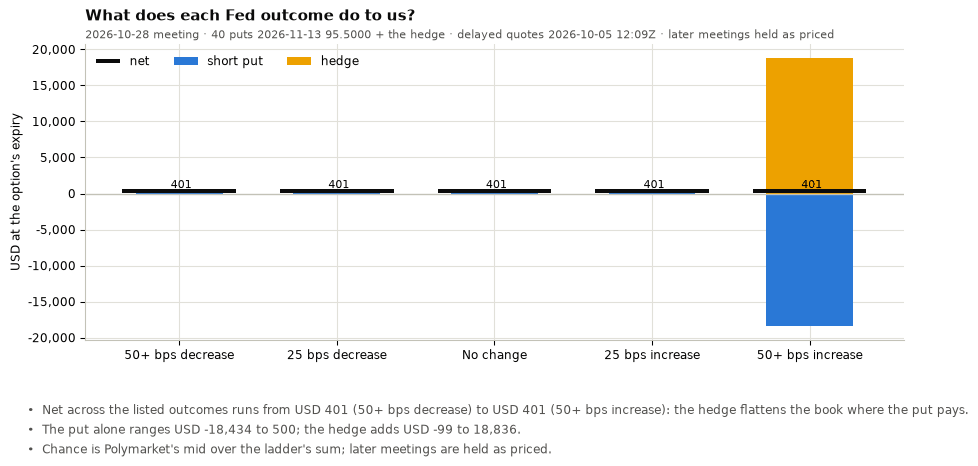

In [7]:
GRID_T = pd.DataFrame(SC.scenario_grid(TRADE, usd_per_bp=USD_PER_BP, sofr_now=SOFR["rate"]))
display(Markdown(GRID_T[["outcome", "chance_pct", "put_pnl_usd", "hedge_pnl_usd", "net_usd"]]
                 .rename(columns={"outcome": "scenario", "chance_pct": "Polymarket's chance, %", "put_pnl_usd": "short put, USD",
                                  "hedge_pnl_usd": "hedge, USD", "net_usd": "net, USD"}).to_markdown(index=False, floatfmt=",.2f")))
fx, ax = plt.subplots(figsize=(11, 4.4))
netbars(ax, GRID_T, GRID_T.outcome)
ask(ax, "What does each Fed outcome do to us?",
    f"{FRONT['end']} meeting · {LOTS} puts {PUT['expiry']} {PUT['strike']:.4f} + the hedge · delayed quotes {RUN_AT} · later meetings held as priced")
ax.set_ylabel("USD at the option's expiry")
W3, B3 = GRID_T.loc[GRID_T.net_usd.idxmin()], GRID_T.loc[GRID_T.net_usd.idxmax()]
show(fx, "fig:s3-scenarios", [
    f"Net across the listed outcomes runs from USD {W3.net_usd:,.0f} ({W3.outcome}) to USD {B3.net_usd:,.0f} ({B3.outcome}): the hedge flattens the book where the put pays.",
    f"The put alone ranges USD {GRID_T.put_pnl_usd.min():,.0f} to {GRID_T.put_pnl_usd.max():,.0f}; the hedge adds USD {GRID_T.hedge_pnl_usd.min():,.0f} to {GRID_T.hedge_pnl_usd.max():,.0f}.",
    "Chance is Polymarket's mid over the ladder's sum; later meetings are held as priced."], kind="scenario-payoff")

**Sizes and returns.** Every size, on the USD 1M equity: what we keep if the Fed does what is priced, what we expect at
Polymarket's odds, and the worst listed outcome, each as USD, % of equity and annualised to the option's expiry.

In [8]:
RET = pd.DataFrame(SC.returns_table(TRADE, GRID_T.to_dict("records"), lots=LOT_SIZES, equity=EQUITY, asof=NOW))
DAYS = int(RET.days.iloc[0])
display(Markdown(RET[["lots", "premium_usd", "hedge_cost_usd", "priced_net_usd", "priced_roe_pct", "priced_ann_pct",
                      "expected_net_usd", "expected_ann_pct", "worst_net_usd", "worst_pct_equity"]]
                 .rename(columns={"lots": "lots", "premium_usd": "premium in", "hedge_cost_usd": "hedge out",
                                  "priced_net_usd": "net if as priced", "priced_roe_pct": "% of equity", "priced_ann_pct": "annualised %",
                                  "expected_net_usd": "expected net", "expected_ann_pct": "expected, annualised %",
                                  "worst_net_usd": "worst outcome", "worst_pct_equity": "worst, % of equity"})
                 .to_markdown(index=False, floatfmt=",.2f") + f"\n\n_{DAYS} days to the option's expiry; USD {EQUITY:,.0f} equity; delayed quotes {RUN_AT}_"))
BASE = RET[RET.lots == LOTS].iloc[0]

| lots | premium in | hedge out | net if as priced | % of equity | annualised % | expected net | expected, annualised % | worst outcome | worst, % of equity |
|---|---|---|---|---|---|---|---|---|---|
| 10 | 125.00 | 24.85 | 100.15 | 0.01 | 0.09 | 100.15 | 0.09 | 100.15 | 0.01 |
| 20 | 250.00 | 49.70 | 200.30 | 0.02 | 0.19 | 200.31 | 0.19 | 200.30 | 0.02 |
| 40 | 500.00 | 99.39 | 400.61 | 0.04 | 0.37 | 400.62 | 0.37 | 400.61 | 0.04 |
| 80 | 1,000.00 | 198.76 | 801.24 | 0.08 | 0.75 | 801.24 | 0.75 | 801.24 | 0.08 |
| 160 | 2,000.00 | 397.53 | 1,602.47 | 0.16 | 1.50 | 1,602.47 | 1.50 | 1,602.47 | 0.16 |

_39 days to the option's expiry; USD 1,000,000 equity; delayed quotes 2026-10-05 12:09Z_

## S4 · Robustness

### S4.1 · 3. Is there an opportunity?

| question | gate |
|---|---|
| Does CME's option market imply a bigger chance of the surprise hike than Polymarket charges for it? | CME's implied chance of the hedged outcomes, minus Polymarket's all-in price, above the S1.1 threshold |

CME's chance is read from put spreads across listed strikes. It also catches the market re-pricing LATER meetings, so
with no gap at all it should sit a little above Polymarket's.

**CME pays us 22.00% for the chance of more than No change; Polymarket charges 17.50c to cover it; the gap is +377 bp of USD 1.** (delayed CME, live Polymarket, 2026-10-05 12:09Z)

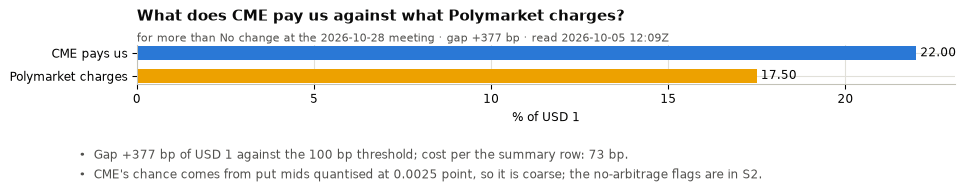

In [9]:
OPP = SC.opportunity(TRADE, STRIP)
ROWS, ONE = pd.DataFrame(OPP["rows"]), OPP["summary"]
NET_EDGE_BPS = float(ONE["gap_bps"])
display(Markdown(f"**CME pays us {ONE['cme_pct']:.2f}% for the chance of {ONE['outcome']}; Polymarket charges "
                 f"{ONE['pm_ask_c']:.2f}c to cover it; the gap is {NET_EDGE_BPS:+.0f} bp of USD 1.** (delayed CME, live Polymarket, {RUN_AT})"))
fx, ax = plt.subplots(figsize=(11, 1.9))
ax.barh([1, 0], [ONE["cme_pct"], ONE["pm_ask_c"]], color=[C_PUT, C_HEDGE], height=.6)
ax.set_yticks([1, 0], ["CME pays us", "Polymarket charges"]); ax.set_xlabel("% of USD 1")
for y, v in ((1, ONE["cme_pct"]), (0, ONE["pm_ask_c"])):
    ax.text(v, y, f" {v:.2f}", va="center", fontsize=9)
ask(ax, "What does CME pay us against what Polymarket charges?", f"for {ONE['outcome']} at the {FRONT['end']} meeting · gap {NET_EDGE_BPS:+.0f} bp · read {RUN_AT}")
show(fx, "fig:s4-one-line", [
    f"Gap {NET_EDGE_BPS:+.0f} bp of USD 1 against the {GAP_MIN_BPS:.0f} bp threshold; cost per the summary row: {ONE['cost_bps']:.0f} bp.",
    "CME's chance comes from put mids quantised at 0.0025 point, so it is coarse; the no-arbitrage flags are in S2."], top=0.55)

| outcome | CME implies, % | Polymarket mid, c | Polymarket ask, c | gap, bp of USD 1 |
|---|---|---|---|---|
| 50+ bps decrease | 2.00 | 0.25 | 0.30 | 168.50 |
| 25 bps decrease | 12.00 | 0.45 | 0.50 | 1147.51 |
| No change | 64.00 | 83.50 | 84.00 | -2067.20 |
| 25 bps increase | 20.00 | 16.50 | 17.00 | 229.45 |
| 50+ bps increase | 2.00 | 0.45 | 0.50 | 147.51 |

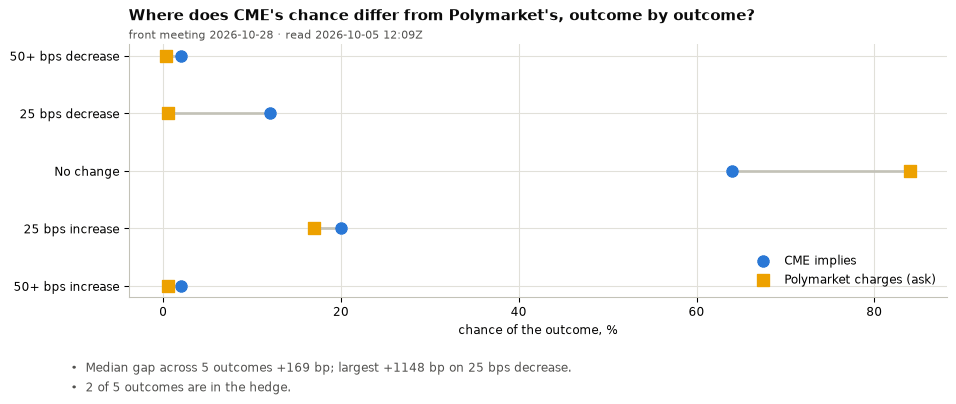

In [10]:
display(Markdown(ROWS[["outcome", "cme_pct", "pm_mid_c", "pm_ask_c", "gap_bps"]]
                 .rename(columns={"cme_pct": "CME implies, %", "pm_mid_c": "Polymarket mid, c", "pm_ask_c": "Polymarket ask, c",
                                  "gap_bps": "gap, bp of USD 1"}).to_markdown(index=False, floatfmt=".2f")))
fx, ax = plt.subplots(figsize=(11, 3.8))
y = np.arange(len(ROWS))[::-1]
ax.hlines(y, ROWS.cme_pct, ROWS.pm_ask_c, color=AXIS, lw=2)
ax.scatter(ROWS.cme_pct, y, s=70, color=C_PUT, zorder=3, label="CME implies")
ax.scatter(ROWS.pm_ask_c, y, s=70, marker="s", color=C_HEDGE, zorder=3, label="Polymarket charges (ask)")
ax.set_yticks(y, ROWS.outcome); ax.set_xlabel("chance of the outcome, %")
ask(ax, "Where does CME's chance differ from Polymarket's, outcome by outcome?", f"front meeting {FRONT['end']} · read {RUN_AT}")
ax.legend(frameon=False, loc="lower right")
show(fx, "fig:s4-outcomes", [
    f"Median gap across {len(ROWS)} outcomes {ROWS.gap_bps.median():+.0f} bp; largest {ROWS.gap_bps.max():+.0f} bp on {ROWS.loc[ROWS.gap_bps.idxmax(), 'outcome']}.",
    f"{int(ROWS.hedged.sum())} of {len(ROWS)} outcomes are in the hedge."])

## S5 · Risk and diagnostics

### S5.1 · 4. The put and the hedge, on the days the put traded

| question | gate |
|---|---|
| What has the put we would sell really traded at, and what did the hedge cost on the same days? | none: real prints only, as the owner chose; no day is filled in |

Individual SR3 options trade rarely, so this is a few dots, not a line. It grows by one daily chain snapshot a day.

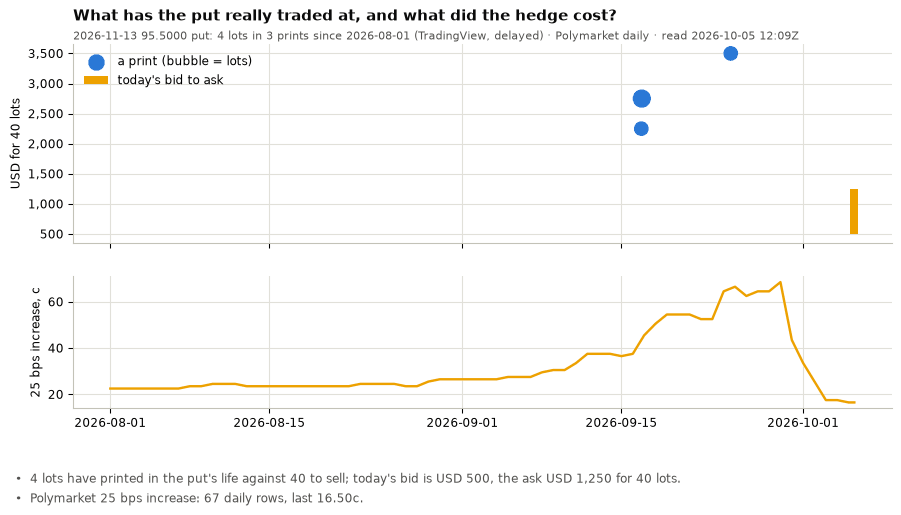

In [11]:
PMH = pd.DataFrame(HD.load(HD.pull("predmkts", "polymarket", HEDGE[0]["token"], "1d", HISTORY_FROM)))
PRN["t"], PMH["t"] = pd.to_datetime(PRN.t, unit="ms"), pd.to_datetime(PMH.t, unit="ms")
PRN["usd"] = [SC.premium_usd(c, LOTS, USD_PER_BP) for c in PRN.c]
BID_USD, ASK_USD = SC.premium_usd(PUT["bid"], LOTS, USD_PER_BP), SC.premium_usd(PUT["ask"], LOTS, USD_PER_BP)
fx, (a0, a1) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
a0.scatter(PRN.t, PRN.usd, s=40 + 60 * PRN.v, color=C_PUT, zorder=3, label="a print (bubble = lots)")
a0.vlines(pd.Timestamp(NOW).tz_convert(None), BID_USD, ASK_USD, color=C_HEDGE, lw=6, label="today's bid to ask")
a0.yaxis.set_major_formatter(USD); a0.set_ylabel(f"USD for {LOTS} lots"); a0.legend(frameon=False, loc="upper left")
a1.plot(PMH.t, PMH.p * 100, color=C_HEDGE, lw=1.8); a1.set_ylabel(f"{HEDGE[0]['outcome']}, c")
ask(a0, "What has the put really traded at, and what did the hedge cost?",
    f"{PUT['expiry']} {PUT['strike']:.4f} put: {PRINTED} lots in {len(PRN)} prints since {HISTORY_FROM} (TradingView, delayed) · Polymarket daily · read {RUN_AT}")
show(fx, "fig:s5-prints", [
    f"{PRINTED} lots have printed in the put's life against {LOTS} to sell; today's bid is USD {BID_USD:,.0f}, the ask USD {ASK_USD:,.0f} for {LOTS} lots.",
    f"Polymarket {HEDGE[0]['outcome']}: {len(PMH)} daily rows, last {PMH.p.iloc[-1] * 100:.2f}c."], top=0.78, kind="series-and-distribution")

## S6 · Decision

### S6.1 · 5 and 6. Hedge size, and the December trade - same format

| question | gate |
|---|---|
| What does each hedge size do in each scenario, and can we buy it? What does the trade as sent do across two meetings? | the loss-matched hedge fills on today's book under the S1.1 cap |

No position is taken: a human arms anything that can lose money.

| outcome | loss-matched | no hedge | your 22,013 YES |
|---|---|---|---|
| 50+ bps decrease | 401 | 500 | 384 |
| 25 bps decrease | 401 | 500 | 384 |
| No change | 401 | 500 | 384 |
| 25 bps increase | 401 | 500 | 384 |
| 50+ bps increase | 401 | -18,434 | 3,463 |

| size | yes | cost_usd |
|---|---|---|
| no hedge | 0 | 0 |
| loss-matched | 18935 | 99 |
| your 22,013 YES | 22013 | 116 |

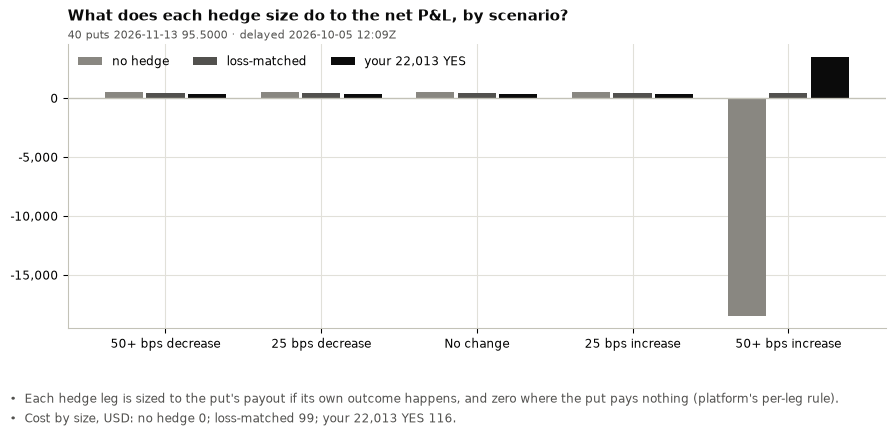

**Can we buy the loss-matched hedge on today's book?**

| outcome | YES wanted | filled | average price, c |
|---|---|---|---|
| 25 bps increase | 0 | 0.00 |  |
| 50+ bps increase | 18935 | 18,935.00 | 0.50 |

In [12]:
HS = SC.hedge_sizes(TRADE, sizes={"no hedge": 0.0, "loss-matched": 1.0, f"your {OWN_YES:,} YES": OWN_YES}, usd_per_bp=USD_PER_BP)
HT = pd.DataFrame(HS["by_scenario"])
display(Markdown(HT.pivot(index="outcome", columns="size", values="net_usd").loc[GRID_T.outcome].to_markdown(floatfmt=",.0f")
                 + "\n\n" + pd.DataFrame(HS["cost"]).drop(columns="legs").to_markdown(index=False, floatfmt=",.0f")))
fx, ax = plt.subplots(figsize=(11, 4.2))
sizes = list(dict.fromkeys(HT["size"]))
x = np.arange(len(GRID_T)); w = .8 / len(sizes)
for i, (sz, c) in enumerate(zip(sizes, C_SIZES)):
    v = HT[HT["size"] == sz].set_index("outcome").loc[GRID_T.outcome].net_usd
    ax.bar(x + (i - (len(sizes) - 1) / 2) * w, v, w * .92, color=c, label=sz)
ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(x, GRID_T.outcome); ax.yaxis.set_major_formatter(USD); ax.legend(frameon=False, ncol=3)
ask(ax, "What does each hedge size do to the net P&L, by scenario?", f"{LOTS} puts {PUT['expiry']} {PUT['strike']:.4f} · delayed {RUN_AT}")
HC = pd.DataFrame(HS["cost"])
show(fx, "fig:s6-hedge", [
    "Each hedge leg is sized to the put's payout if its own outcome happens, and zero where the put pays nothing (platform's per-leg rule).",
    "Cost by size, USD: " + "; ".join(f"{r['size']} {r['cost_usd']:,.0f}" for _, r in HC.iterrows()) + "."], kind="scenario-payoff")
FILL = [MATCH.walk_asks(PM.book(h["token"]), h["yes"], h["row"], cap=WALK_CAP) for h in HEDGE]
FILL_T = pd.DataFrame([{"outcome": h["outcome"], "YES wanted": h["yes"], "filled": f["filled"], "average price, c": f["avg"] * 100}
                       for h, f in zip(HEDGE, FILL)])
display(Markdown("**Can we buy the loss-matched hedge on today's book?**\n\n" + FILL_T.to_markdown(index=False, floatfmt=",.2f")))

| path | chance, % | short Dec put, USD | hedge, USD | net, USD |
|---|---|---|---|---|
| No change, 25 bps increase | 57.89 | 1,000.00 | -923.17 | 76.83 |
| No change, No change | 20.65 | 1,000.00 | -923.17 | 76.83 |
| 25 bps increase, 25 bps increase | 11.44 | 1,000.00 | -923.17 | 76.83 |
| 25 bps increase, No change | 4.08 | 1,000.00 | -923.17 | 76.83 |
| No change, 50+ bps increase | 2.75 | 1,000.00 | 21,089.83 | 22,089.83 |
| 50+ bps decrease, 50+ bps decrease | 0.00 | 1,000.00 | -923.17 | 76.83 |

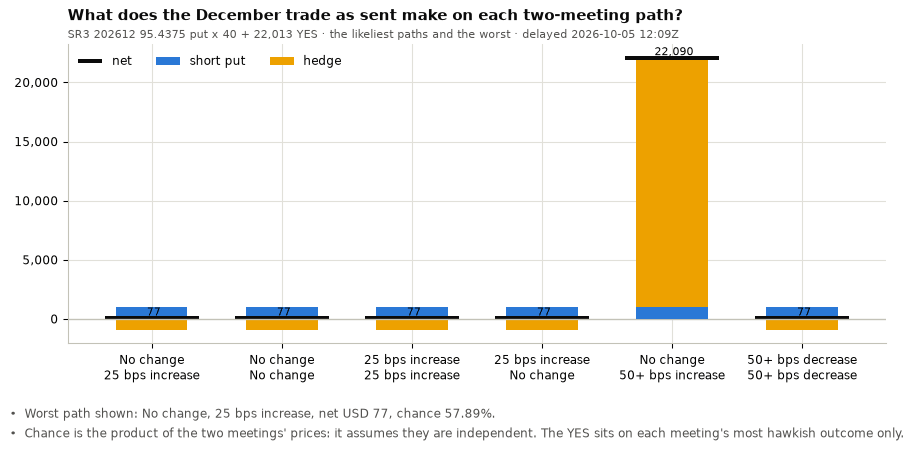

| id | section | gate | reading | threshold | verdict | would change it |
|---|---|---|---|---|---|---|
| D1 | S2 | every put at the expiry has a bid and an ask no wider than the S1.1 limit | 39 of 92 puts two-sided inside 0.0100 points; 22 one-sided, 31 wider | all | **FLAG** | a strip that quotes wide or one-sided |
| D2 | S2 | put quotes rise with strike, convexly, inside their bounds | 330/346 checks | all | **FAIL** | a stale or wide quote in the strip |
| D3 | S2 | the put we sell has printed at least our size in its life | 4 lots in 3 prints, against 40 to sell | >= 40 lots | **FLAG** | the put trading in size |
| G1 | S4 | CME's implied chance of the surprise beats Polymarket's all-in price | +377 bp of USD 1 | >= 100 bp | **PASS** | either price moving; the bid we would really get |
| G2 | S6 | the loss-matched hedge fills on today's book under the cap | 25 bps increase 0/0 · 50+ bps increase 18,935/18,935 | all filled under 20c | **PASS** | depth on the outcome's book |

In [13]:
OWN = SC.two_meeting_grid(CHAIN, [FRONT, NEXT], LADDER, expiry_month=OWN_EXPIRY_MONTH, strike=OWN_STRIKE, lots=LOTS,
                          yes=OWN_YES, usd_per_bp=USD_PER_BP, trade=TRADE)
PT = pd.DataFrame(OWN["paths"])
display(Markdown(PT[["path", "chance_pct", "put_pnl_usd", "hedge_pnl_usd", "net_usd"]]
                 .rename(columns={"chance_pct": "chance, %", "put_pnl_usd": "short Dec put, USD", "hedge_pnl_usd": "hedge, USD", "net_usd": "net, USD"})
                 .to_markdown(index=False, floatfmt=",.2f")))
fx, ax = plt.subplots(figsize=(11, 4.4))
netbars(ax, PT, [p.replace(", ", "\n") for p in PT.path])
ask(ax, "What does the December trade as sent make on each two-meeting path?",
    f"SR3 {OWN_EXPIRY_MONTH} {OWN_STRIKE:.4f} put x {LOTS} + {OWN_YES:,} YES · the likeliest paths and the worst · delayed {RUN_AT}")
WP = PT.loc[PT.net_usd.idxmin()]
show(fx, "fig:s6-december", [
    f"Worst path shown: {WP.path}, net USD {WP.net_usd:,.0f}, chance {WP.chance_pct:.2f}%.",
    "Chance is the product of the two meetings' prices: it assumes they are independent. The YES sits on each meeting's most hawkish outcome only."],
     kind="scenario-payoff")
GATES = D_GATES + [
    {"id": "G1", "section": "S4", "label": "CME pays more", "name": "CME's implied chance of the surprise beats Polymarket's all-in price",
     "reading": f"{NET_EDGE_BPS:+.0f} bp of USD 1", "threshold": f">= {GAP_MIN_BPS:.0f} bp",
     "verdict": "PASS" if NET_EDGE_BPS >= GAP_MIN_BPS else "FAIL", "would_change": "either price moving; the bid we would really get"},
    {"id": "G2", "section": "S6", "label": "Hedge fills", "name": "the loss-matched hedge fills on today's book under the cap",
     "reading": " · ".join(f"{r['outcome']} {r['filled']:,.0f}/{r['YES wanted']:,.0f}" for _, r in FILL_T.iterrows()),
     "threshold": f"all filled under {WALK_CAP*100:.0f}c", "verdict": "PASS" if (FILL_T.filled >= FILL_T["YES wanted"]).all() else "FLAG",
     "would_change": "depth on the outcome's book"}]
WORD = "CHECK DATA" if any(g["verdict"] == "FAIL" for g in D_GATES) else ("GAP" if GATES[3]["verdict"] == "PASS" else "NO GAP")
display(Markdown(REPORT.gate_table_md(GATES)))

## S7 · Verdict

In [14]:
WORST = GRID_T.loc[GRID_T.net_usd.idxmin()]
IMPL = [f"CME pays us {ONE['cme_pct']:.2f}% for {ONE['outcome']}; Polymarket charges {ONE['pm_ask_c']:.2f}c: a gap of {NET_EDGE_BPS:+.0f} bp ({RUN_AT}).",
        f"At {LOTS} lots, as priced, we keep USD {BASE.priced_net_usd:,.0f}: {BASE.priced_roe_pct:.2f}% of equity, {BASE.priced_ann_pct:.1f}% annualised over {DAYS} days.",
        f"At Polymarket's odds we expect USD {BASE.expected_net_usd:,.0f} ({BASE.expected_ann_pct:.1f}% annualised).",
        f"With the hedge on, every listed outcome nets between USD {GRID_T.net_usd.min():,.0f} and USD {GRID_T.net_usd.max():,.0f}; the worst, {WORST.outcome}, is {BASE.worst_pct_equity:.2f}% of equity.",
        "A move bigger than the largest listed outcome keeps costing the put while the YES pays the same USD 1: the hedge caps one step, not the tail."]
WHY = [f"CME pays {ONE['cme_pct']:.1f}% for {ONE['outcome']}; Polymarket charges {ONE['pm_ask_c']:.1f}c: a gap of {NET_EDGE_BPS:+.0f} bp",
       f"At {LOTS} lots, as priced, we keep USD {BASE.priced_net_usd:,.0f}: {BASE.priced_roe_pct:.2f}% of equity"]
CAVEATS = ["a snapshot of today's prices, not a backtest: no past P&L or win rate exists for this trade",
           f"SR3 quotes are TradingView's, CME {DELAY_MIN} min delayed: a quote is not a fill, and the put has barely traded (D3)",
           "the live chain, Polymarket books and history are live reads, unpinned: a re-run reads new prices",
           "later meetings are held as priced; a re-pricing of them moves the put and not the hedge",
           "CME's implied chances are undiscounted put spreads and include later-meeting re-pricing",
           "two-meeting chances multiply the two meetings' prices, which assumes they are independent",
           f"this is the read of {RUN_AT}; the registered 2026-10-04 values below are typed, not re-read"]
assert all(len(c_) <= 110 for c_ in CAVEATS + WHY), [len(c_) for c_ in CAVEATS + WHY]
VERDICT = {"word": WORD, "why": WHY, "next": {"metric": "net_edge_bps", "predict": "the gap on a daily re-read", "window": "the next 5 trade dates"}}
LAB = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lab" / "research").is_dir()) / "lab" / "research" / "data" / "runs.jsonl"
PRE = next((json.loads(l) for l in LAB.read_text(encoding="utf-8").splitlines() if l.strip() and json.loads(l).get("run") == RUN_ID
            and json.loads(l).get("stage") == "preflight"), None)
assert PRE is not None, f"{RUN_ID} is not pre-registered: run preregister.py before this notebook"
GOT = {"net_edge_bps": NET_EDGE_BPS, "premium_usd": float(PUT["premium_usd"]), "priced_ann_pct": float(BASE.priced_ann_pct),
       "worst_pct_equity": float(BASE.worst_pct_equity)}
BAND = pd.DataFrame({k: {"registered band": v, "this run": GOT.get(k),
                         "in band": float(v.split("..")[0]) <= GOT[k] <= float(v.split("..")[1])} for k, v in PRE["predicted"].items()}).T
display(Markdown(f"**This is the read of {RUN_AT}** (CME quotes {DELAY_MIN} minutes delayed, TradingView, [API] fact card read {DELAY['read']}; Polymarket live). "
                 "It is a new read, not a replication: the market has moved since the registered read."))
display(Markdown("\n".join([f"**Verdict: {WORD}.**"] + [f"- {s}" for s in IMPL] + [f"- Caveat: {c}" for c in CAVEATS])))
# ---- the registered 2026-10-04 read of research-008, typed from its notebook [1], beside this read ----
H50 = next((h for h in HEDGE if h["outcome"] == "50+ bps increase"), None)
FILL50 = next((f for h, f in zip(HEDGE, FILL) if h["outcome"] == "50+ bps increase"), None)
REGISTERED = [
    ("put sold", "2026-11-13 95.5000", f"{PUT['expiry']} {PUT['strike']:.4f}"),
    ("put bid / ask, points", "0.0075 / 0.0150", f"{PUT['bid']:.4f} / {PUT['ask']:.4f}"),
    (f"premium in, {LOTS} lots, USD", "750", f"{PUT['premium_usd']:,.0f}"),
    ("Polymarket ask, 50+ bps increase, c", "0.50", "n/a" if H50 is None else f"{H50['ask'] * 100:.2f}"),
    ("YES filled / wanted, 50+ bps increase", "18,894 / 18,894", "n/a" if FILL50 is None else f"{FILL50['filled']:,.0f} / {H50['yes']:,.0f}"),
    ("CME implies for the hedged outcomes, %", "22.00", f"{ONE['cme_pct']:.2f}"),
    ("Polymarket ask for them, c", "17.50", f"{ONE['pm_ask_c']:.2f}"),
    ("gap, bp of USD 1", "+377", f"{NET_EDGE_BPS:+.0f}"),
    ("net if as priced, USD", "651", f"{BASE.priced_net_usd:,.0f}"),
    ("verdict word", "CHECK DATA", WORD)]
REGTAB = pd.DataFrame([{"quantity": q, "registered read 2026-10-04 14:37Z [1], not re-read": a, f"this read {RUN_AT}": b, "same at the digits shown": "yes" if a == b else "no"}
                       for q, a, b in REGISTERED])
display(Markdown("**The registered read beside this one.**\n\n" + REGTAB.to_markdown(index=False)
                 + "\n\nThe registered column is typed from the 2026-10-04 notebook, with its tag [1]; it is not re-read. A row that agrees is a determinism check of "
                 "an unchanged market, never a replication; a row that differs is the market having moved between the two reads."))
display(Markdown(f"Pre-registered bands of {RUN_ID} (set for the 2026-10-04 read), against this read:\n\n" + BAND.to_markdown(floatfmt=",.2f")))
print("metrics for remeasure.py: " + " ".join(f"{k}={v:.2f}" for k, v in GOT.items()))

**This is the read of 2026-10-05 12:09Z** (CME quotes 10 minutes delayed, TradingView, [API] fact card read 2026-09-28; Polymarket live). It is a new read, not a replication: the market has moved since the registered read.

**Verdict: CHECK DATA.**
- CME pays us 22.00% for more than No change; Polymarket charges 17.50c: a gap of +377 bp (2026-10-05 12:09Z).
- At 40 lots, as priced, we keep USD 401: 0.04% of equity, 0.4% annualised over 39 days.
- At Polymarket's odds we expect USD 401 (0.4% annualised).
- With the hedge on, every listed outcome nets between USD 401 and USD 401; the worst, 50+ bps decrease, is 0.04% of equity.
- A move bigger than the largest listed outcome keeps costing the put while the YES pays the same USD 1: the hedge caps one step, not the tail.
- Caveat: a snapshot of today's prices, not a backtest: no past P&L or win rate exists for this trade
- Caveat: SR3 quotes are TradingView's, CME 10 min delayed: a quote is not a fill, and the put has barely traded (D3)
- Caveat: the live chain, Polymarket books and history are live reads, unpinned: a re-run reads new prices
- Caveat: later meetings are held as priced; a re-pricing of them moves the put and not the hedge
- Caveat: CME's implied chances are undiscounted put spreads and include later-meeting re-pricing
- Caveat: two-meeting chances multiply the two meetings' prices, which assumes they are independent
- Caveat: this is the read of 2026-10-05 12:09Z; the registered 2026-10-04 values below are typed, not re-read

**The registered read beside this one.**

| quantity | registered read 2026-10-04 14:37Z [1], not re-read | this read 2026-10-05 12:09Z | same at the digits shown |
|---|---|---|---|
| put sold | 2026-11-13 95.5000 | 2026-11-13 95.5000 | yes |
| put bid / ask, points | 0.0075 / 0.0150 | 0.0050 / 0.0125 | no |
| premium in, 40 lots, USD | 750 | 500 | no |
| Polymarket ask, 50+ bps increase, c | 0.50 | 0.50 | yes |
| YES filled / wanted, 50+ bps increase | 18,894 / 18,894 | 18,935 / 18,935 | no |
| CME implies for the hedged outcomes, % | 22.00 | 22.00 | yes |
| Polymarket ask for them, c | 17.50 | 17.50 | yes |
| gap, bp of USD 1 | +377 | +377 | yes |
| net if as priced, USD | 651 | 401 | no |
| verdict word | CHECK DATA | CHECK DATA | yes |

The registered column is typed from the 2026-10-04 notebook, with its tag [1]; it is not re-read. A row that agrees is a determinism check of an unchanged market, never a replication; a row that differs is the market having moved between the two reads.

Pre-registered bands of research-008 (set for the 2026-10-04 read), against this read:

| index | registered band | this run | in band |
|---|---|---|---|
| net_edge_bps | 1000..3500 | 376.96 | False |
| premium_usd | 500..1000 | 500.00 | True |
| priced_ann_pct | 0.2..1.2 | 0.37 | True |
| worst_pct_equity | 0..0.15 | 0.04 | True |

metrics for remeasure.py: net_edge_bps=376.96 premium_usd=500.00 priced_ann_pct=0.37 worst_pct_equity=0.04


In [15]:
# ---- the research summary card (fundplat.quant.core.summary_card): every value read from the run's own objects above; the manifest carries it and the last cell draws it ----
from fundplat.quant.core import summary_card
from IPython.display import HTML
FILLED = float(FILL_T.filled.sum()) / max(float(FILL_T["YES wanted"].sum()), 1.0) * 100
METRICS = {"n_opportunities": len(ROWS), "median_gap_bps": float(ROWS.gap_bps.median()),
           "cost_bps": float(ONE["cost_bps"]), "net_edge_bps": NET_EDGE_BPS, "capture_pct": np.nan, "fill_share_pct": FILLED,
           "capacity_usd": float(sum(f["filled"] * f["avg"] for f in FILL if f["filled"] > 0)), "half_life_h": np.nan, "persistence_pct": np.nan,
           "n_venues": 2, "ann_return_pct": float(BASE.expected_ann_pct), "sharpe": np.nan}
NA = {"capture_pct": "one snapshot: nothing was captured",
      "half_life_h": "not fitted on one option's life", "persistence_pct": "not fitted on one option's life",
      "sharpe": "a scenario analysis has no return series"}
WINDOW = {"from": f"{PMH.t.min():%Y-%m-%dT%H:%MZ}", "to": NOW.strftime("%Y-%m-%dT%H:%MZ"),
          "hours": int((pd.Timestamp(NOW).tz_convert(None) - PMH.t.min()).total_seconds() // 3600), "regimes": 1}
VERIFY = {"suite": "sr3_scenarios.verify", **SC.verify_summary(), "books": 1}
G_ = {g_["id"]: g_ for g_ in GATES}
FAILED = [g_["id"] for g_ in D_GATES if g_["verdict"] == "FAIL"]
mk = lambda metric, value, bar="", verdict="", **kw: {"metric": metric, "value": value, "bar": bar, "verdict": verdict, **kw}
GAP_BEFORE_BPS = (float(ONE["cme_pct"]) - float(ONE["pm_ask_c"])) * 100.0
assert abs(GAP_BEFORE_BPS - float(ONE["cost_bps"]) - NET_EDGE_BPS) < 1e-6, (GAP_BEFORE_BPS, ONE["cost_bps"], NET_EDGE_BPS)
ANSWER = (f"{WORD}. Read {RUN_AT}: CME pays {ONE['cme_pct']:.1f}% for {ONE['outcome']}, Polymarket charges {ONE['pm_ask_c']:.1f}c, a gap of {NET_EDGE_BPS:+.0f} bp after the hedge cost."
          + (f" {len(FAILED)} data check failed, so no gap is called." if FAILED else ""))
IMPL_CARD = [("Trade", f"Short {LOTS} SR3 puts, long Polymarket hike YES"),
             ("Put", f"SR3 {PUT['expiry']} {PUT['strike']:.4f}, sold at the bid"),
             ("Hedge", "Polymarket YES at the ask, sized to the put's loss"),
             ("Prices", f"CME {DELAY_MIN} min late [API]; Polymarket live [API]"),
             ("Capital", f"USD {EQUITY:,.0f}; every return is on that"),
             ("Read", f"{RUN_AT}; a snapshot, not a backtest")]
# a gap read off quotes that fail a data check is not a verdict: the big number is INFO with no gate tie, and the headline names no gate, so the list shows no tone
BIG_GAP = (mk("CME minus Polymarket, after hedge cost", f"{NET_EDGE_BPS:+.0f} bp", f"hurdle {GAP_MIN_BPS:.0f} bp; data fails", "INFO", key="net_edge_bps") if FAILED
           else mk("CME minus Polymarket, after hedge cost", f"{NET_EDGE_BPS:+.0f} bp", f"at least {GAP_MIN_BPS:.0f} bp", G_["G1"]["verdict"], key="net_edge_bps", gate="G1"))
BIG = [dict(BIG_GAP, scope="gap"),
       dict(mk("Net if the Fed does what is priced", f"USD {BASE.priced_net_usd:+,.0f}", "", "INFO"), scope=f"{LOTS} lots"),
       dict(mk("Worst listed outcome, of equity", f"{BASE.worst_pct_equity:+.2f}%", "", "INFO"), scope="worst"),
       dict(mk("Loss-matched hedge filled", f"{FILLED:.0f}%", f"under {WALK_CAP * 100:.0f}c", G_["G2"]["verdict"], key="fill_share_pct", gate="G2"), scope="hedge")]
BLOCKS = [
    {"title": "The gap", "rows": [mk("CME implies", f"{ONE['cme_pct']:.1f}%"), mk("Polymarket ask", f"{ONE['pm_ask_c']:.1f}c"),
        mk("Gap before costs", f"{GAP_BEFORE_BPS:+.0f} bp"),
        mk("Cost of the hedge side", f"{ONE['cost_bps']:.1f} bp", key="cost_bps"),
        mk("Gap after hedge cost", f"{NET_EDGE_BPS:+.0f} bp", f"at least {GAP_MIN_BPS:.0f} bp", G_["G1"]["verdict"], key="net_edge_bps", gate="G1"), mk(f"Median gap, {len(ROWS)} outcomes", f"{ROWS.gap_bps.median():+.1f} bp", key="median_gap_bps"),
        mk("Outcomes compared", str(len(ROWS)), key="n_opportunities")]},
    {"title": f"Returns, {LOTS} lots", "rows": [mk("Premium in", f"USD {BASE.premium_usd:,.0f}"), mk("Hedge out", f"USD {BASE.hedge_cost_usd:,.0f}"),
        *([mk("Net in every listed outcome", f"USD {BASE.priced_net_usd:+,.0f}")] if abs(BASE.priced_net_usd - BASE.worst_net_usd) < 0.5
          else [mk("Net if as priced", f"USD {BASE.priced_net_usd:+,.0f}"), mk("Worst listed outcome", f"USD {BASE.worst_net_usd:+,.0f}")]),
        mk("Of equity", f"{BASE.priced_roe_pct:+.2f}%"),
        mk("Expected at Polymarket's odds, ann.", f"{BASE.expected_ann_pct:+.1f}%", key="ann_return_pct")]},
    {"title": "Data checks", "rows": [mk("Puts with two-sided quotes", f"{len(STRIP) - WIDE - ONE_SIDED} of {len(STRIP)}", f"{len(STRIP)} of {len(STRIP)}", G_["D1"]["verdict"], gate="D1"),
        mk("No-arbitrage checks passed", f"{ARB['passed']} of {ARB['total']}", f"{ARB['total']} of {ARB['total']}", G_["D2"]["verdict"], gate="D2"),
        mk("Lots the put has printed", f"{PRINTED} of {LOTS}", f"at least {LOTS} lots", G_["D3"]["verdict"], gate="D3"),
        mk("Scenario checks passed", f"{VERIFY['passed']} of {VERIFY['total']}")]},
    {"title": "Hedge and December trade", "rows": [mk("Capacity at today's asks", f"USD {METRICS['capacity_usd']:,.0f}", key="capacity_usd"),
        mk("Worst December path, net", f"USD {WP.net_usd:+,.0f}"), mk("Chance of that path", f"{WP.chance_pct:.2f}%")]}]
SAME_NET = all(abs(r_.priced_net_usd - r_.worst_net_usd) < 0.5 for r_ in RET.itertuples())
SIZES = {"cols": ["Lots, information only", "Net in every listed outcome" if SAME_NET else "Net if as priced", "Annualised", *([] if SAME_NET else ["Worst listed outcome"]), "Verdict"],
         "chosen": int(list(RET.lots).index(LOTS)),
         "rows": [[f"{int(r_.lots)}", f"USD {r_.priced_net_usd:+,.0f}", f"{r_.priced_ann_pct:+.1f}%", *([] if SAME_NET else [f"USD {r_.worst_net_usd:+,.0f}"]), "INFO"] for r_ in RET.itertuples()]}
FOOT = ["Next test: re-read the gap daily for the next 5 trade dates; a gap that holds above the bar is the case for the trade.",
        f"Not a fill: the quotes are CME {DELAY_MIN} minutes late and the put has printed {PRINTED} lots against {LOTS} to sell.",
        "Not a backtest: no past P&L or win rate; later meetings are held as priced; two-meeting chances assume independence."]
CARD = {"question": "Does CME pay more for a surprise Fed hike than Polymarket charges to cover it, and what does each outcome do to the hedged put?",
        "answer": ANSWER, "implementation": IMPL_CARD, "big": BIG, "blocks": BLOCKS, "sizes": SIZES, "footer": FOOT}
from fundplat.data import handle as HANDLE
INPUTS = HANDLE.pin_reads(f"study input: {STUDY_ID}", f"research:{RUN_ID}")
INPUTS["unpinned"] += [{"what": f"tradingview:option_chain {UNDERLYING}", "why": "a live read (class NONE), CME 10 minutes delayed; not stored"},
                       {"what": "polymarket:fed-rates events, live books, daily price history", "why": "live reads (class NONE); prediction-market history is not pinned"}]
RULES = {"entry": "sell the put at the bid, buy the hedge at the ask",
         "exit": "none: no exit modelled, P&L read at the put's expiry",
         "sizing": f"{LOTS} puts; YES sized to the put's loss if its outcome pays",
         "rebalance": None,
         "hedge": "Polymarket YES on the hike outcomes above the likeliest",
         "hold": "to the put's expiry",
         "stop": "none: a snapshot, no stop is modelled",
         "cost": "spread crossed: put at the bid, hedge at the ask"}
assert all(v_ is None or len(v_) <= 60 for v_ in RULES.values()), {k_: len(v_) for k_, v_ in RULES.items() if v_}
PARAMS = {"equity": {"value": EQUITY, "unit": "usd", "source": "owner: the capital every return is measured on"},
          "lots": {"value": LOTS, "unit": "contracts", "source": "owner 2026-09-27: 40 SR3 puts"},
          "own_yes": {"value": OWN_YES, "unit": "YES", "source": "owner 2026-09-27: the YES count in the trade as sent"},
          "usd_per_bp": {"value": USD_PER_BP, "unit": "usd", "source": f"{CARD_FACTS['USD per bp per contract']['tag']} CME fact card read {CARD_FACTS['USD per bp per contract']['read']}"},
          "strike_below_bp": {"value": STRIKE_BELOW_BP, "unit": "bp", "source": "[U] the put sits about one 25 bp surprise below the future"},
          "max_spread_pts": {"value": MAX_SPREAD_PTS, "unit": "pts", "source": "[U] a wider put quote is flagged"},
          "walk_cap": {"value": WALK_CAP, "unit": "usd", "source": "[U] the highest Polymarket ask a hedge walk pays"},
          "gap_min_bps": {"value": GAP_MIN_BPS, "unit": "bp", "source": "[U] the gap a trade needs"},
          "history_from": {"value": HISTORY_FROM, "source": "[U] how far back prints and history are read"}}
assert FAILED or G_["G1"]["label"] == "CME pays more"   # the headline gate, named only while every data check holds
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind=KIND, desk=DESK, title=TITLE, question=QUESTION, status="registered",
    run={"executed": NOW.strftime("%Y-%m-%dT%H:%MZ"), "kernel": "ccvenv", "run_id": RUN_ID}, inputs=INPUTS, window=WINDOW, verify=VERIFY,
    gates=GATES, figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    sections=REPORT.sections({"S6": "no position; a human arms"}),
    headline={"metric": "net_edge_bps", "label": "CME vs PM gap", "value": NET_EDGE_BPS, "unit": "bp", "hurdle": GAP_MIN_BPS, **({} if FAILED else {"gate": "G1"})},
    components=[{"name": "put premium", "usd": float(PUT["premium_usd"])}, *[{"name": f"hedge {h['outcome']}", "usd": -float(h["cost_usd"])} for h in HEDGE]],
    profile={"market": "rates", "markets": ["rates", "predmkts"], "venues": ["cme", "polymarket"],
             "instruments": [f"SR3 put {PUT['expiry']} {PUT['strike']:.4f}", *[f"Polymarket {h['outcome']}" for h in HEDGE]], "bar": "1h"},
    rules=RULES, params=PARAMS, style="discretionary", summary=CARD,
    book={"at": RUN_AT, "legs": [{"side": "SELL", "instrument": f"SR3 put {PUT['expiry']} {PUT['strike']:.4f}", "qty": LOTS, "usd": float(PUT["premium_usd"])},
                                 *[{"side": "BUY", "instrument": f"Polymarket {h['outcome']}", "qty": float(h["yes"]), "usd": float(h["cost_usd"])} for h in HEDGE]]},
    format="rel_value", metrics=METRICS, na={k: v for k, v in NA.items() if not np.isfinite(METRICS[k])})
assert not REPORT.card_problems(CARD, carry=False), REPORT.card_problems(CARD, carry=False)
S0_HANDLE.update(Markdown(REPORT.summary_md(STUDY)))
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 5 gates, 6 figures, verdict CHECK DATA

## A · Appendix

n/a - every table is shown in its section.

## Research summary

The card the Research room shows: the question, the answer, the numbers that matter.

In [16]:
# ---- the research summary: the card was built before the manifest and rides in its summary; this is the same card, drawn ----
display(HTML(summary_card.render(CARD, carry=False)))

"Lots, information only",Net in every listed outcome,Annualised,Verdict
10,USD +100,+0.1%,INFO
20,USD +200,+0.2%,INFO
40,USD +401,+0.4%,INFO
80,USD +801,+0.7%,INFO
160,"USD +1,602",+1.5%,INFO
